# Week 4 — Introduction to scikit-learn II
## From packing-time predictions to model selection

**Guiding question:** Before packing starts, can we rank orders by their risk of taking more than 15 minutes to pack?

This notebook is preparation material for independent study. Run the cells in order, read the explanations and pause at the self-checks. All examples include complete code. The orders are **simulated**, not evidence about a real warehouse. Their generating process is available in the project, but try investigating the data first.

### Learning goals

By the end, you will be able to turn a prediction question into two classes, explain a ROC curve and its AUC, prepare inputs for a model, and compare models using several training and validation splits. You will also see how to choose model settings systematically and assess the selected approach on orders kept aside for a final test. Each of these ideas is introduced below.

Keep asking: **What is our question? What is our baseline? How do we evaluate the result? What can we conclude?**

## 1. Load and understand the data

One row represents one order. The CSV is in the project-level `data` folder. In Binder, open this notebook from its week folder and execute the cells from top to bottom. The path below also works when the working directory is the project root.

We start by examining the orders available for our prediction task.

In [88]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebook and data folder are both in the project root.
data_path = Path("data/orders.csv")

# Read the file into a DataFrame and inspect its size and first rows.
orders = pd.read_csv(data_path)
print("Rows and columns:", orders.shape)
orders.head()

Rows and columns: (2000, 9)


,order_id,item_count,fragile_count,storage_zones,gift_wrap,total_weight_kg,order_value_eur,package_side_cm,packing_time_min
0,1,2,0,2,0,4.00,28.01,18.81,3.83
1,2,16,3,4,1,26.82,141.27,47.62,30.90
2,3,14,1,3,1,35.53,159.21,39.17,27.00
3,4,9,1,3,0,2.42,92.97,18.33,11.58
4,5,9,2,2,0,19.22,89.29,34.81,16.62


Each row represents one order. Its **features** are the pieces of information we may give a model as inputs. Here these are known before packing begins:

| Feature | Meaning |
|---|---|
| `item_count` | Number of items in the order |
| `fragile_count` | Number of items that need careful handling |
| `storage_zones` | Number of warehouse areas from which items are collected |
| `gift_wrap` | Whether gift wrapping was requested: 1 for yes, 0 for no |
| `total_weight_kg` | Total weight in kilograms |
| `order_value_eur` | Order value in euros |
| `package_side_cm` | Side length in centimetres of the planned cubic package |

Two other columns have different roles. `order_id` identifies a row; it does not describe the order. `packing_time_min` is observed **after** packing has finished. We can use it to construct the outcome we want to predict, but we cannot give it to a model that predicts before packing.

Inspect the column types, missing values and distributions before deciding how to use the data.

In [89]:
# Check column types, missing values and repeated identifiers.
print(orders.dtypes)
print("\nMissing values:\n", orders.isna().sum())
print("\nDuplicate IDs:", orders["order_id"].duplicated().sum())

# Summarize numeric columns; round the displayed statistics.
orders.describe().round(2)

order_id              int64
item_count            int64
fragile_count         int64
storage_zones         int64
gift_wrap             int64
total_weight_kg     float64
order_value_eur     float64
package_side_cm     float64
packing_time_min    float64
dtype: object

Missing values:
 order_id            0
item_count          0
fragile_count       0
storage_zones       0
gift_wrap           0
total_weight_kg     0
order_value_eur     0
package_side_cm     0
packing_time_min    0
dtype: int64

Duplicate IDs: 0


,order_id,item_count,fragile_count,storage_zones,gift_wrap,total_weight_kg,order_value_eur,package_side_cm,packing_time_min
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,1000.50,10.49,2.11,2.31,0.18,14.91,188.76,32.06,17.36
std,577.49,5.80,1.72,1.12,0.39,11.58,162.26,10.37,9.42
min,1.00,1.00,0.00,1.00,0.00,0.20,3.73,15.00,0.92
25%,500.75,5.00,1.00,1.00,0.00,5.51,74.73,23.32,9.54
50%,1000.50,11.00,2.00,2.00,0.00,11.87,147.74,31.70,16.17
75%,1500.25,16.00,3.00,3.00,0.00,22.15,257.87,40.07,24.05
max,2000.00,20.00,9.00,4.00,1.00,52.35,1300.27,55.00,47.26


**Self-check:** Which column would give the answer away if used as a feature?

## 2. Construct the target

In week 3 the goal was to predict a number of minutes. Here the goal is to decide which of two groups an order belongs to: this is **binary classification**. We call the outcome to predict the **target**.

We define a long order as one taking **more than** 15 minutes: class 1. An order taking 15 minutes or less belongs to class 0. The 15-minute boundary represents an example business decision, such as deciding which orders may need additional preparation. We fix this definition before comparing models. Let's see how common each class is.

             count  proportion
over_15_min                   
0              925      0.4625
1             1075      0.5375


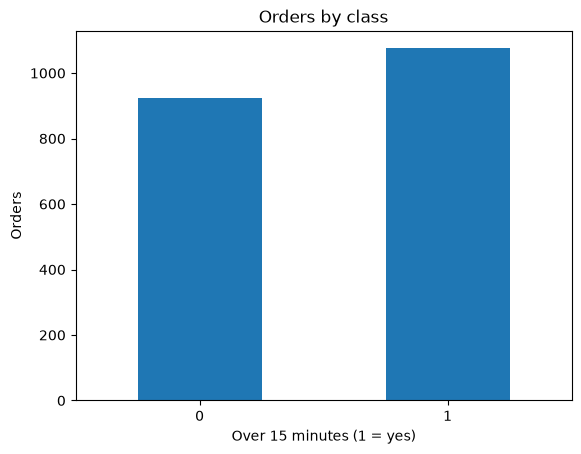

In [90]:
# The comparison produces True/False; astype(int) converts these to 1/0.
orders["over_15_min"] = (orders["packing_time_min"] > 15).astype(int)

# Count each class, then divide by the number of orders for its share.
counts = orders["over_15_min"].value_counts().sort_index()
print(pd.DataFrame({"count": counts, "proportion": counts / len(orders)}))
counts.plot.bar(rot=0, title="Orders by class", xlabel="Over 15 minutes (1 = yes)", ylabel="Orders")
plt.show()

**Accuracy** is the fraction of predictions that are correct. Imagine 95 of 100 orders are short: always predicting ‘short’ would give 95% accuracy, while failing to identify any of the five long orders. When one class is much more frequent than the other, we call this **class imbalance**. Whether missing rare cases matters depends on the application.

The next cell explores how the class proportions would change with different definitions of a long order. Our actual target remains fixed at 15 minutes.

In [91]:
# This loop changes only the illustration; it does not change our target.
for threshold in [15, 25, 35]:
    print(f"Over {threshold} minutes: {(orders['packing_time_min'] > threshold).mean():.1%}")

Over 15 minutes: 53.8%
Over 25 minutes: 22.4%
Over 35 minutes: 4.5%


## 3. Reserve a test set

Before comparing models, we reserve 20% of the orders as a **test set**. These orders are set aside until the end, so they can provide a check on choices made using the other 80%. We call those remaining orders the **training data**. The split keeps approximately the same proportion of long orders in each group.

This is a random split, suitable for illustrating our independently simulated orders. For real orders arriving over time, a split based on past and future may be more appropriate. We exclude the identifier and the observed packing time from the model inputs.

In [92]:
from sklearn.model_selection import train_test_split

# X contains inputs available before packing; y contains the target.
features = ["item_count", "fragile_count", "storage_zones", "gift_wrap",
            "total_weight_kg", "order_value_eur", "package_side_cm"]
X = orders[features].copy()
y = orders["over_15_min"].copy()

# Reserve 20% for testing; stratify approximately preserves class proportions.
# random_state makes this particular split reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train/test sizes:", len(X_train), len(X_test))
print("Positive proportion — train:", round(y_train.mean(), 3), "test:", round(y_test.mean(), 3))

Train/test sizes: 1600 400
Positive proportion — train: 0.538 test: 0.538


## 4. Scores, decisions and confusion matrices

A model can give each order a **score**: a higher score indicates stronger evidence that it is long. Our models will provide estimated probabilities between 0 and 1; a score of 0.8 is an estimate, not a guarantee that the order will be long.

To make a yes/no decision, we choose a **threshold**. At a threshold of 0.5, a score of 0.8 is classified as long and a score of 0.3 as short. Comparing predictions with actual outcomes gives four possibilities:

| Actual order | Model prediction | Name |
|---|---|---|
| Long | Long | True positive (TP) |
| Short | Long | False positive (FP) |
| Short | Short | True negative (TN) |
| Long | Short | False negative (FN) |

A **confusion matrix** counts these outcomes. The consequences of the two kinds of mistake depend on the decision: unnecessary preparation and an unexpected delay can have different costs.

This tiny example is independent of our training and test data.

In [93]:
from sklearn.metrics import confusion_matrix
# Six known outcomes and example scores, in matching order.
example_y = np.array([0, 1, 0, 1, 1, 0])
example_scores = np.array([0.10, 0.80, 0.40, 0.60, 0.30, 0.70])

# Apply each threshold, then unpack the four confusion-matrix counts.
for threshold in [0.5, 0.3]:
    predictions = (example_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(example_y, predictions, labels=[0, 1]).ravel()
    print(f"Threshold {threshold}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Threshold 0.5: TN=2, FP=1, FN=1, TP=2
Threshold 0.3: TN=1, FP=2, FN=0, TP=3


**Self-check:** Before rerunning, predict how lowering the threshold changes the number of positive predictions. Does a lower threshold necessarily reduce false positives?

## 5. ROC curve and ROC-AUC

The **true positive rate** (TPR, also called recall) is `TP / (TP + FN)`: among actual long orders, the fraction identified as long. The **false positive rate** (FPR) is `FP / (FP + TN)`: among actual short orders, the fraction incorrectly flagged as long. Their denominators are different: one considers only long orders and the other only short orders. For example, if we flag 8 of 10 long orders, TPR is 0.8; if we also flag 2 of 10 short orders, FPR is 0.2.

The **ROC curve** (receiver operating characteristic curve) plots FPR on the horizontal axis against TPR on the vertical axis as we vary the decision threshold. A high threshold usually gives few positive predictions; lowering it gives more. Each point corresponds to a threshold. A point closer to the upper left means a high TPR and a low FPR at that threshold. Let's calculate several points from our example.

In [94]:
# Calculate a point on the ROC curve for each chosen threshold.
for threshold in [1.0, 0.7, 0.5, 0.3, 0.0]:
    pred = (example_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(example_y, pred, labels=[0, 1]).ravel()
    print(f"threshold={threshold:.1f}  FPR={fp/(fp+tn):.2f}  TPR={tp/(tp+fn):.2f}")

threshold=1.0  FPR=0.00  TPR=0.00
threshold=0.7  FPR=0.33  TPR=0.33
threshold=0.5  FPR=0.33  TPR=0.67
threshold=0.3  FPR=0.67  TPR=1.00
threshold=0.0  FPR=1.00  TPR=1.00


`roc_curve` calculates points across the score thresholds. ROC-AUC is the **area under this curve**. It summarizes ranking across thresholds rather than judging one chosen threshold.

Imagine randomly choosing one long and one short order. An AUC of 0.8 means that, over such pairs, the long order receives the higher score about 80% of the time, counting tied scores as half a correct ranking. This is not the percentage of orders classified correctly. A constant score cannot distinguish orders and has an AUC of 0.5; perfect ranking has an AUC of 1.0. An AUC below 0.5 means the scores rank this sample in the opposite direction more often than not.

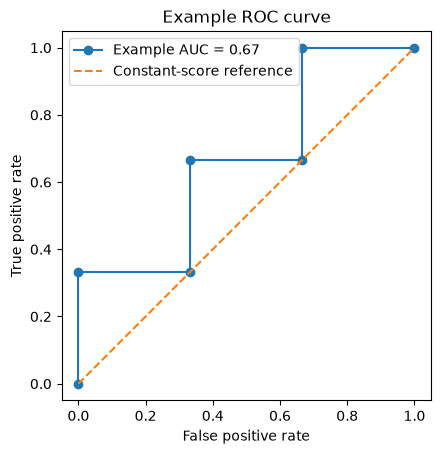

   threshold       FPR       TPR
0        inf  0.000000  0.000000
1        0.8  0.000000  0.333333
2        0.7  0.333333  0.333333
3        0.6  0.333333  0.666667
4        0.4  0.666667  0.666667
5        0.3  0.666667  1.000000
6        0.1  1.000000  1.000000


In [95]:
from sklearn.metrics import roc_curve, roc_auc_score
# Compute the curve and its area from the true labels and scores.
fpr, tpr, thresholds = roc_curve(example_y, example_scores)
example_auc = roc_auc_score(example_y, example_scores)

# Plot the model curve and the diagonal constant-score reference.
plt.plot(fpr, tpr, marker="o", label=f"Example AUC = {example_auc:.2f}")
plt.plot([0, 1], [0, 1], "--", label="Constant-score reference")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Example ROC curve")
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.show()
print(pd.DataFrame({"threshold": thresholds, "FPR": fpr, "TPR": tpr}))

**Self-check:** If we reverse every score, what happens to the ranking? Why does a good AUC not tell us which threshold to use?

AUC tells us how well the scores **rank** orders: are long orders usually given higher scores than short orders? It does not answer every question about those scores.

For example, suppose a model assigns a 0.8 score to many orders. If we interpret 0.8 as an 80% probability, we might expect roughly 80% of those orders to be long. Checking whether predicted probabilities match observed frequencies is called **calibration**. A model can rank orders well while its probabilities are too high or too low.

AUC also does not tell us which score threshold to choose. Flagging a short order may waste preparation time; failing to flag a long order may cause a delay. To choose a threshold, we would need to consider what these mistakes cost in our application.

If long orders are very rare, we may also want to know: of the orders we flag as long, how many actually are long? This fraction is called **precision**. Recall, introduced above as the true positive rate, is the fraction of all actual long orders that we flag. A precision-recall curve shows how these two fractions change as the threshold changes.

Finally, ROC-AUC needs **both actual classes** in the data being evaluated: without long orders there is no positive group to compare, and without short orders there is no negative group.

## 6. Scaling and feature engineering

Different columns use different units: item counts, euros and cubic centimetres can have very different magnitudes. `StandardScaler` learns a mean and standard deviation **for each feature** and transforms a value to `(value - mean) / standard deviation`. Training values have mean approximately 0 and standard deviation 1; this does not make them normally distributed. Bringing features to comparable scales can help the training algorithm and influences how strongly a penalty on model weights affects each feature.

For example, if training orders have a mean weight of 10 kg and a standard deviation of 5 kg, an order weighing 15 kg becomes `(15 - 10) / 5 = 1`. The value 1 means one training standard deviation above the training mean. The scaler stores the training mean and standard deviation so that it can transform later orders in exactly the same way, even one order at a time.

The next small example is separate from our model data. In the actual comparison, the scaler learns its values separately within each training fold.

In [96]:
from sklearn.preprocessing import StandardScaler
# Two-dimensional input: three observations and one feature.
example_values = np.array([[10.0], [20.0], [30.0]])
demo_scaler = StandardScaler()
print("Original:", example_values.ravel())

# fit_transform learns the mean and standard deviation and applies them.
print("Standardized:", demo_scaler.fit_transform(example_values).ravel().round(3))

Original: [10. 20. 30.]
Standardized: [-1.225  0.     1.225]


**Feature engineering** means creating additional model inputs from information we already have. For example, a cube with sides of 10 cm has volume `10 × 10 × 10 = 1,000 cm³`. The derived value does not require a new measurement; it presents the existing side length in a different form.

The six candidate features below express different hypotheses about packing. They may help a model, make no meaningful difference, or make its predictions worse. `item_count` and `storage_zones` are positive in this dataset, so the divisions are defined.

| Option | Calculation | What it describes |
|---|---|---|
| `package_volume` | side length cubed | Volume of the planned cubic box |
| `average_weight` | total weight ÷ items | Average weight per item |
| `average_price` | order value ÷ items | Average order value per item |
| `fragile_share` | fragile items ÷ items | Fraction of items that are fragile |
| `items_per_zone` | items ÷ storage zones | Average number of items per area visited |
| `items_times_zones` | items × storage zones | A combined measure of order size and areas visited |

The dictionary controls which extra features are added. `True` includes a feature and `False` leaves it out. Models labelled `Original` use only the original seven features. `Selected extras` adds the enabled features to those seven. We start with volume and items multiplied by zones.

In [97]:
# Turn an additional feature on with True or off with False.
feature_options = {
    "package_volume": True,
    "average_weight": False,
    "average_price": False,
    "fragile_share": False,
    "items_per_zone": False,
    "items_times_zones": True,
}

We want to compare models using the original information with models that also receive selected combinations. A transformer makes those calculations repeatable inside a pipeline: it receives a table and returns a copy with the chosen columns added. Its `fit` method does not need to estimate values here because the formulas are fixed; its `transform` method applies those formulas to each table it receives.

In [98]:
from sklearn.base import BaseEstimator, TransformerMixin

# This scikit-learn compatible transformer adds the enabled columns.
class AddOrderFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, options=None):
        self.options = options

    # No quantities need to be learned for these formulas.
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Work on a copy so the original table stays unchanged.
        result = X.copy()
        options = self.options or {}

        # Each enabled option adds one column calculated from existing inputs.
        if options.get("package_volume", False):
            result["package_volume_cm3"] = X["package_side_cm"] ** 3
        if options.get("average_weight", False):
            result["average_weight"] = X["total_weight_kg"] / X["item_count"]
        if options.get("average_price", False):
            result["average_price"] = X["order_value_eur"] / X["item_count"]
        if options.get("fragile_share", False):
            result["fragile_share"] = X["fragile_count"] / X["item_count"]
        if options.get("items_per_zone", False):
            result["items_per_zone"] = X["item_count"] / X["storage_zones"]
        if options.get("items_times_zones", False):
            result["items_times_zones"] = X["item_count"] * X["storage_zones"]

        return result

# Preview the selected transformations on five training orders. fit_transform() is a convenience method that calls fit() and then transform().
AddOrderFeatures(feature_options).fit_transform(X_train.head())

,item_count,fragile_count,storage_zones,gift_wrap,total_weight_kg,order_value_eur,package_side_cm,package_volume_cm3,items_times_zones
876,11,1,1,0,22.14,52.20,31.66,31734.578296,11
1756,7,3,2,1,10.47,96.65,25.59,16757.562879,14
848,17,3,4,1,9.67,276.96,45.27,92775.111183,68
667,18,2,2,0,36.04,462.57,40.85,68167.314125,36
1216,11,1,1,0,19.89,140.63,27.18,20079.290232,11


## 7. Pipelines and cross-validation

A pipeline applies steps in sequence: add features, scale, and fit a model. To fit a scaler means to calculate and store the mean and standard deviation of each feature. During cross-validation, each fold calculates these values using **only that fold's training rows**, then uses the stored values to transform both its training and validation rows. This keeps the validation orders separate when we evaluate the model on data it has not seen.

In week 3 we used one fixed validation set to compare choices. Here, **cross-validation** makes several comparisons within the training data. We divide those data into three parts, called **folds**:

| Run | Used to fit the pipeline | Used to validate it |
|---|---|---|
| 1 | Folds 2 and 3 | Fold 1 |
| 2 | Folds 1 and 3 | Fold 2 |
| 3 | Folds 1 and 2 | Fold 3 |

Each run starts with a fresh model and scaler. Its validation fold represents unseen orders for that run; the separate test set is still untouched. **Stratified** means the folds are arranged to have approximately similar proportions of the two classes. We compare the three AUC values and their mean, rather than relying on one particular split.

Our first model is **logistic regression**. Despite its name, it can classify orders: it combines the input features and produces an estimated probability for class 1. It is a useful simpler model to compare with a neural network. Here, a constant score for every order provides an even simpler reference: its AUC is 0.5.

In [99]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# Reuse the same reproducible stratified folds for all comparisons.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Build the same sequence for either model; passthrough skips scaling.
def make_pipeline(model, options=None, scale=True):
    return Pipeline([
        ("features", AddOrderFeatures(options)),
        ("scaler", StandardScaler() if scale else "passthrough"),
        ("model", model),
    ])

# Evaluate logistic regression with original features on the training folds.
# Logistic regression is a model used for binary classification that predicts the probability of a positive outcome.
baseline = make_pipeline(LogisticRegression(max_iter=2000, random_state=42))
scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="roc_auc")

print("Fold AUCs:", scores.round(3))
print(f"Mean: {scores.mean():.3f}; fold standard deviation: {scores.std():.3f}")

Fold AUCs: [0.99  0.987 0.992]
Mean: 0.990; fold standard deviation: 0.002


**Self-check:** Compare the three fold AUCs above with the constant-score reference of 0.5. Does the model rank long and short orders better than a score that is the same for every order? Are the fold results similar, or do they vary?

The fold standard deviation summarizes how much these three AUC values differ from their mean. A smaller value means these particular fold results are closer together. Three folds alone do not tell us exactly how the model will perform on every possible new dataset.

## 8. A small neural network

The network receives the features, processes them through one or more **hidden layers**, then outputs a score for class 1. Each layer contains units called neurons. The connections between them have numbers called **weights**; training adjusts these weights to make useful predictions. Additional layers allow the network to build combinations of the patterns found by earlier layers. A larger network is not guaranteed to predict better.

A model can fit peculiarities of its training orders that do not hold for new orders. To discourage this, we can add a penalty for large weights during training. This is called **L2 regularization**. The setting `alpha` controls the penalty strength: a larger value penalizes large weights more strongly. Too much penalty can also make the model too inflexible, so we compare settings using cross-validation.

Our first example has one hidden layer with eight neurons, written `(8,)`. In the search below, `(8, 8)` means two layers of eight neurons and `(8, 8, 8)` means three. A convergence warning means that training stopped without meeting its stopping criterion; investigate such warnings when interpreting results.

In [100]:
# One hidden layer with 8 neurons; alpha sets the penalty on large weights.
network = make_pipeline(MLPClassifier(hidden_layer_sizes=(8,), alpha=0.01,
                                      max_iter=1000, random_state=42))
network_scores = cross_val_score(network, X_train, y_train, cv=cv, scoring="roc_auc")

print("Network fold AUCs:", network_scores.round(3))
print(f"Mean: {network_scores.mean():.3f}; fold standard deviation: {network_scores.std():.3f}")

Network fold AUCs: [0.99  0.986 0.991]
Mean: 0.989; fold standard deviation: 0.002


## 9. Search hyperparameters and compare four candidates

During training a model learns **parameters**, such as the weights of its connections. **Hyperparameters** are settings chosen before training, such as the number of hidden layers. Different settings may work better or worse for new orders.

`GridSearchCV` automates the comparison: for each candidate setting it trains and validates a fresh pipeline on each fold, averages the validation AUC values, and chooses the setting with the highest mean. It then fits that setting again on all training orders. This does not use the separate test set. The double underscore in `model__C` connects a setting to the pipeline step named `model`.

For logistic regression, `C` controls the strength of a penalty on model weights: a smaller `C` means stronger regularization. For the neural network, a larger `alpha` means stronger regularization. Regularization encourages smaller weights; it does not guarantee better predictions. We try two values of each setting and one, two or three hidden layers for the network.

The two models use appropriate, different grids. Each model is evaluated with original features and with the selected additions. ROC-AUC uses scores, not hard class predictions. In the results table, `neurons_per_layer` lists the number of neurons in each hidden layer, so `8 → 8` means two layers with eight neurons each. `C` applies to logistic regression; `alpha` and `neurons_per_layer` apply to the neural network.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define one small search grid per model; model__ refers to the pipeline step.
model_specs = {
    "Logistic regression": (LogisticRegression(max_iter=2000, random_state=42),
                            {"model__C": [0.1, 1.0]}),
    "Neural network": (MLPClassifier(max_iter=1000, random_state=42),
                       {"model__hidden_layer_sizes": [(8,), (8, 8), (8, 8, 8)],
                        "model__alpha": [0.01, 0.1]}),
}

# Keep the fitted searches and their summary rows for later comparison.
searches = {}
rows = []

# For each model, search once with original and once with additional features.
for model_name, (model, grid) in model_specs.items():
    for feature_set, options in [("Original", None), ("Selected extras", feature_options)]:
        search = GridSearchCV(make_pipeline(model, options), grid, cv=cv,
                              scoring="roc_auc", refit=True, n_jobs=1)
        # Fit and compare settings using only the training data and CV folds.
        search.fit(X_train, y_train)

        key = (model_name, feature_set)
        searches[key] = search
        best = search.best_index_
        # Put each setting in its own column so the table remains readable.
        params = search.best_params_
        layers = params.get("model__hidden_layer_sizes")
        rows.append({"model": model_name, "features": feature_set,
                     "mean_auc": search.best_score_,
                     "fold_std": search.cv_results_["std_test_score"][best],
                     "C": params.get("model__C", None),
                     "alpha": params.get("model__alpha", None),
                     "neurons_per_layer": "–" if layers is None else " → ".join(str(size) for size in layers)})

# Show the strongest cross-validation mean first.
results = pd.DataFrame(rows).sort_values("mean_auc", ascending=False)
results

Read `mean_auc` as the average of the three validation AUCs and `fold_std` as a summary of how much those three values differ. The listed settings are the best of the candidates we tried, not necessarily the best settings possible.

Some settings can look better partly because of the particular orders in these folds. When we pick the largest of several estimates, it may be optimistic. A tiny difference alone does not establish a universal winner. Consider model simplicity, variation across folds and the fact that these data are synthetic.

**Self-check:** Did the engineered features help each model? Does an improvement establish that the new feature caused packing time to change?

## 10. Investigate scaling

We compare scaling on and off for the same default model settings and selected extra features, using the same folds. This is a controlled illustration, not another hyperparameter grid. The values need not match the tuned results above. Training may reach its iteration limit, especially without scaling; the corresponding AUC should be interpreted with care. If you use this comparison to choose a final approach, it becomes part of model selection.

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Repeat each default model on the same folds with and without scaling.
scale_rows = []

# Hide only convergence warnings inside this block, keeping the output readable.
# These warnings mean training reached a limit before its stopping criterion.
# Hiding them does not fix the issue; unscaled results need particular care.
# Other warning types remain visible, and the filter ends with this block.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)

    for name, (model, _) in model_specs.items():
        for scale in [True, False]:
            pipe = make_pipeline(model, feature_options, scale=scale)
            fold_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
            scale_rows.append({"model": name, "scaled": scale,
                               "mean_auc": fold_scores.mean(), "fold_std": fold_scores.std()})

pd.DataFrame(scale_rows)

,model,scaled,mean_auc,fold_std
0,Logistic regression,True,0.989670,0.002276
1,Logistic regression,False,0.989138,0.001502
2,Neural network,True,0.986878,0.001465
3,Neural network,False,0.619413,0.210687


## 11. Select and evaluate once on the test set

For this worked example we select the highest mean cross-validation AUC among the four **scaled searches**. For nearly tied results, a simpler model might be a defensible alternative; here we use a reproducible rule. This automatically chosen rule does not select the unscaled demonstration above. The selected search has already refitted its best pipeline on all training rows (training + validation). We now use the previously untouched test set once.

Selected: ('Logistic regression', 'Selected extras') {'model__C': 1.0}
Held-out test ROC-AUC: 0.995


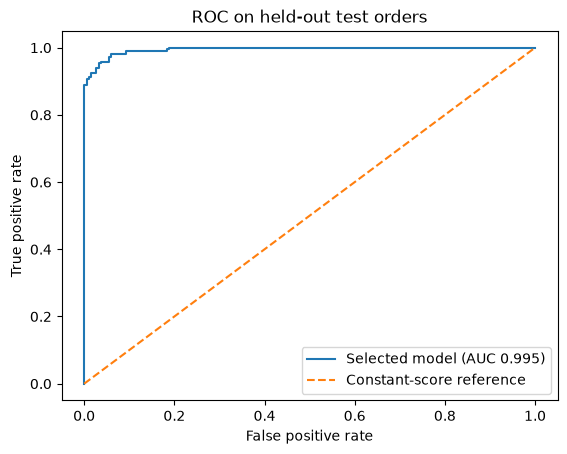

In [ ]:
# Select the top cross-validation result; the test set did not guide this choice.
winner_row = results.iloc[0]
winner_key = (winner_row["model"], winner_row["features"])
winner = searches[winner_key]
print("Selected:", winner_key, winner.best_params_)

# Column 1 contains the predicted score for class 1 (over 15 minutes).
test_scores = winner.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_scores)
test_fpr, test_tpr, _ = roc_curve(y_test, test_scores)
print(f"Held-out test ROC-AUC: {test_auc:.3f}")

plt.plot(test_fpr, test_tpr, label=f"Selected model (AUC {test_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Constant-score reference")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC on held-out test orders")
plt.legend()
plt.show()

The test AUC describes how well the chosen model ranks these held-out orders. It gives an estimate for new orders from the same simulated process; another sample of orders could give a different result. It does not establish performance in a real warehouse. If we repeatedly use this test result to choose features or models, our choices start depending on these orders and the test no longer provides the same independent check.

## 12. Recap and outlook

Answer in your own words:

1. What is the prediction question, and which information is available at prediction time?
2. What is the constant-score baseline and what does ROC-AUC measure?
3. Why must scaling be fitted within each cross-validation fold?
4. Did the additional features or the neural network provide a meaningful advantage? What uncertainty remains?
5. What would you need before using such predictions in a real warehouse?

In a real data project, also consider time ordering, repeated customers or other related observations when choosing a split. The independent simulated orders here do not prove that a random split is suitable in another setting.

## Optional: Your turn

Choose other options in `feature_options`, explain your expectations, and rerun the feature comparison on the **training data**. Consider average price: it may predict packing time indirectly through related order characteristics even though price itself need not cause packing time. If you have already inspected the test result above, treat further experiments as exploratory; a fresh independent test set would be needed for an unbiased final assessment of a newly selected approach.

For a second exploration, compare a different threshold on the small illustrative example and explain the resulting trade-off between false positives and false negatives.